# P1 – EDA giá heo hơi Việt Nam (Mốc 1)

Notebook này tạo toàn bộ sản phẩm của P1 cho mục 4.1: bảng ADF, ma trận tương quan, tương quan trễ thức ăn–giá heo,
thống kê mô tả (Tết 2026, giá giảm cuối kỳ, khác biệt 3 miền).

- Đầu vào: `data/features/data_v1.csv` (P2). Chạy từ thư mục gốc repo hoặc từ `notebooks/`.
- Đầu ra: `results/tables/4_1_*.csv` và `results/figures/4_1_*.png`.
- Chạy lần lượt từ trên xuống bằng *Run All*.

In [1]:
# 1. Khởi tạo
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
IN_NB = "ipykernel" in sys.modules
if not IN_NB:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data/features/data_v1.csv"
TAB = ROOT / "results/tables"
FIG = ROOT / "results/figures"
TAB.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

REGIONS = ["Bac", "Trung", "Nam"]
LABEL = {"Bac": "Bắc", "Trung": "Trung", "Nam": "Nam"}
COLOR = {"Bac": "#1f77b4", "Trung": "#2ca02c", "Nam": "#d62728"}
TET = pd.Timestamp("2026-02-17")  # mùng 1 Tết Bính Ngọ 2026

def save_table(df, name, index=False):
    """Lưu CSV có BOM để Excel mở đúng tiếng Việt."""
    df.to_csv(TAB / name, index=index, encoding="utf-8-sig")
    print("  đã lưu", (TAB / name).relative_to(ROOT))

def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")
    print("  đã lưu", (FIG / name).relative_to(ROOT))
    if IN_NB:
        plt.show()
    else:
        plt.close(fig)

df = pd.read_csv(DATA, parse_dates=["date"])
assert set(df["region"]) == set(REGIONS), "Miền không đúng"
print(df.shape, df["date"].min().date(), "->", df["date"].max().date())

def wide(col, frame=None):
    """Bảng ngày × miền của một cột."""
    f = df if frame is None else frame
    return f.pivot(index="date", columns="region", values=col)[REGIONS]

# Ngày có giá quan sát thật và không phải Chủ nhật chép lại thứ Bảy (dùng cho thống kê mô tả)
obs = df[(df["is_observed"] == 1) & (df["is_sunday_copy"] == 0)].copy()
train_end = df.loc[df["split"] == "train", "date"].max()
val_end = df.loc[df["split"] == "val", "date"].max()

(1458, 74) 2025-07-02 -> 2026-10-30


## 2. ADF (kiểm định tính dừng)

H0: chuỗi **không dừng** (có nghiệm đơn vị). p-value < 0,05 → bác bỏ H0 → chuỗi dừng.
Chạy trên giá miền (`price_ffill`, chuỗi liên tục), chuỗi gốc và sai phân bậc 1, trên toàn bộ mẫu và riêng Train
(Train là mẫu dùng để quyết định bậc sai phân d cho ARIMA, nên không nhìn Val/Test).

In [2]:
rows = []
for sample, mask in [("Toàn bộ", df["date"].notna()), ("Train", df["split"] == "train")]:
    for r in REGIONS:
        s = df[mask & (df["region"] == r)].set_index("date")["price_ffill"].dropna()
        for name, series in [("Gốc", s), ("Sai phân bậc 1", s.diff().dropna())]:
            stat, p, lag, n, crit, _ = adfuller(series, autolag="AIC")
            rows.append({
                "Miền": LABEL[r], "Mẫu": sample, "Chuỗi": name, "n": n, "Số độ trễ": lag,
                "Thống kê ADF": round(stat, 3), "p-value": round(p, 4),
                "Giá trị tới hạn 5%": round(crit["5%"], 3),
                "Kết luận (mức 5%)": "Dừng" if p < 0.05 else "Không dừng",
            })
adf = pd.DataFrame(rows)
save_table(adf, "4_1_adf.csv")
adf

  đã lưu results\tables\4_1_adf.csv


,Miền,Mẫu,Chuỗi,n,Số độ trễ,Thống kê ADF,p-value,Giá trị tới hạn 5%,Kết luận (mức 5%)
0,Bắc,Toàn bộ,Gốc,477,5,-1.240,0.6560,-2.868,Không dừng
1,Bắc,Toàn bộ,Sai phân bậc 1,477,4,-6.165,0.0000,-2.868,Dừng
2,Trung,Toàn bộ,Gốc,475,7,-1.566,0.5009,-2.868,Không dừng
3,Trung,Toàn bộ,Sai phân bậc 1,470,11,-3.931,0.0018,-2.868,Dừng
4,Nam,Toàn bộ,Gốc,475,7,-1.047,0.7356,-2.868,Không dừng
5,Nam,Toàn bộ,Sai phân bậc 1,475,6,-4.500,0.0002,-2.868,Dừng
6,Bắc,Train,Gốc,264,5,-1.678,0.4425,-2.873,Không dừng
7,Bắc,Train,Sai phân bậc 1,264,4,-4.529,0.0002,-2.873,Dừng
8,Trung,Train,Gốc,262,7,-1.846,0.3580,-2.873,Không dừng
9,Trung,Train,Sai phân bậc 1,261,7,-3.309,0.0145,-2.873,Dừng


## 3. Thống kê mô tả: theo miền, theo tháng, giá cuối kỳ

Chỉ dùng các ngày có giá quan sát thật và không phải Chủ nhật chép lại thứ Bảy.

In [3]:
g = obs.groupby("region")["price"]
desc = pd.DataFrame({
    "Số ngày có giá": g.count(),
    "Trung bình": g.mean(), "Độ lệch chuẩn": g.std(),
    "Nhỏ nhất": g.min(), "Q1": g.quantile(0.25), "Trung vị": g.median(),
    "Q3": g.quantile(0.75), "Lớn nhất": g.max(),
}).loc[REGIONS]
desc["Hệ số biến thiên (%)"] = desc["Độ lệch chuẩn"] / desc["Trung bình"] * 100
desc = desc.round(1)
desc.index = [LABEL[r] for r in desc.index]
desc.index.name = "Miền"
save_table(desc.reset_index(), "4_1_desc_by_region.csv")

monthly = (obs.assign(thang=obs["date"].dt.to_period("M").astype(str))
              .groupby(["thang", "region"])["price"].mean().unstack()[REGIONS].round(0))
monthly.columns = [LABEL[r] for r in REGIONS]
save_table(monthly.reset_index().rename(columns={"thang": "Tháng"}), "4_1_monthly_mean.csv")

# Đỉnh và giá cuối kỳ theo miền (trung bình tháng)
end_rows = []
for r in REGIONS:
    m = monthly[LABEL[r]]
    end_rows.append({
        "Miền": LABEL[r],
        "Tháng đầu kỳ": m.index[0], "Giá tháng đầu kỳ": m.iloc[0],
        "Tháng đỉnh": m.idxmax(), "Giá tháng đỉnh": m.max(),
        "Tháng cuối kỳ": m.index[-1], "Giá tháng cuối kỳ": m.iloc[-1],
        "Thay đổi từ đỉnh đến cuối kỳ (%)": round((m.iloc[-1] / m.max() - 1) * 100, 1),
    })
peak_end = pd.DataFrame(end_rows)
save_table(peak_end, "4_1_peak_and_end.csv")
display(desc) if IN_NB else print(desc)
display(peak_end) if IN_NB else print(peak_end)

  đã lưu results\tables\4_1_desc_by_region.csv
  đã lưu results\tables\4_1_monthly_mean.csv
  đã lưu results\tables\4_1_peak_and_end.csv


,Số ngày có giá,Trung bình,Độ lệch chuẩn,Nhỏ nhất,Q1,Trung vị,Q3,Lớn nhất,Hệ số biến thiên (%)
Miền,,,,,,,,,
Bắc,403,62018.4,7078.2,44533.3,56733.3,62933.3,67333.3,80200.0,11.4
Trung,403,60782.8,7063.5,43909.1,56454.5,62181.8,65181.8,77454.5,11.6
Nam,402,61630.3,6690.2,45000.0,57406.2,61937.5,67468.8,76750.0,10.9


,Miền,Tháng đầu kỳ,Giá tháng đầu kỳ,Tháng đỉnh,Giá tháng đỉnh,Tháng cuối kỳ,Giá tháng cuối kỳ,Thay đổi từ đỉnh đến cuối kỳ (%)
0,Bắc,2025-07,64792.0,2026-01,74232.0,2026-10,51105.0,-31.2
1,Trung,2025-07,63684.0,2026-02,73100.0,2026-10,50371.0,-31.1
2,Nam,2025-07,65925.0,2026-02,72382.0,2026-10,51255.0,-29.2


  đã lưu results\tables\4_1_price_wide.csv
  đã lưu results\figures\4_1_price_by_region.png


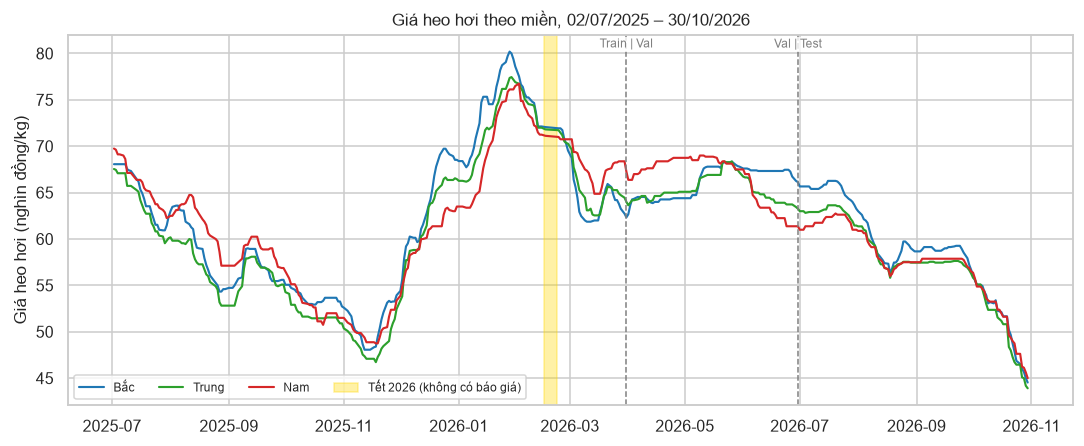

In [4]:
# Dữ liệu giá theo miền dạng bảng ngày × miền, để mở bằng Excel tự vẽ lại biểu đồ
price_wide = wide("price", obs).rename(columns=LABEL)
save_table(price_wide.reset_index().rename(columns={"date": "Ngày"}), "4_1_price_wide.csv")

fig, ax = plt.subplots(figsize=(10, 4.2))
for r in REGIONS:
    s = wide("price", obs)[r].dropna()
    ax.plot(s.index, s.values / 1000, label=LABEL[r], color=COLOR[r], lw=1.4)
ax.axvspan(TET - pd.Timedelta(days=2), TET + pd.Timedelta(days=5), color="gold", alpha=0.35, label="Tết 2026 (không có báo giá)")
for d, t in [(train_end, "Train | Val"), (val_end, "Val | Test")]:
    ax.axvline(d, color="gray", ls="--", lw=1)
    ax.text(d, ax.get_ylim()[1] - 0.4, t, ha="center", va="top", fontsize=8, color="gray",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))
ax.set_ylabel("Giá heo hơi (nghìn đồng/kg)")
ax.set_title("Giá heo hơi theo miền, 02/07/2025 – 30/10/2026")
ax.legend(loc="lower left", ncol=4, fontsize=8)
save_fig(fig, "4_1_price_by_region.png")

  đã lưu results\figures\4_1_price_distribution.png


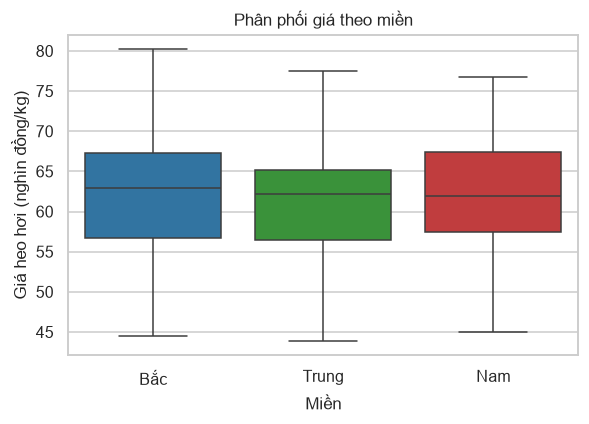

In [5]:
# Phân phối giá theo miền (hộp)
fig, ax = plt.subplots(figsize=(5.5, 4))
d = obs.assign(Miền=obs["region"].map(LABEL), gia=obs["price"] / 1000)
sns.boxplot(data=d, x="Miền", y="gia", order=[LABEL[r] for r in REGIONS],
            palette=[COLOR[r] for r in REGIONS], ax=ax)
ax.set_ylabel("Giá heo hơi (nghìn đồng/kg)")
ax.set_title("Phân phối giá theo miền")
save_fig(fig, "4_1_price_distribution.png")

## 4. Hiệu ứng Tết 2026

Các ngày nghỉ Tết (15–22/02/2026) không có báo giá. So sánh giá 30 ngày trước Tết (`tet_pre30`), 30 ngày sau (`tet_post30`)
và các ngày còn lại. Số liệu mang tính mô tả: mẫu chỉ có **một** Tết và giá còn chịu xu hướng chung của giai đoạn.

  đã lưu results\tables\4_1_tet_effect.csv
  đã lưu results\figures\4_1_tet_window.png


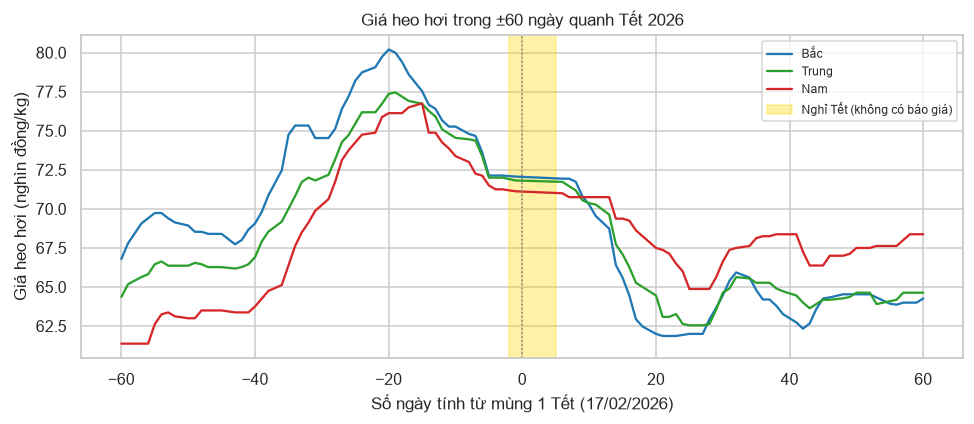

,Miền,Giá TB ngoài giai đoạn Tết,Giá TB 30 ngày trước Tết,Số ngày trước Tết,Giá TB 30 ngày sau Tết,Số ngày sau Tết,Sau so với trước Tết (%),Số ngày có giá trong mùng 1–5
0,Bắc,60805,76221,25,65518,22,-14.0,0
1,Trung,59453,74847,25,66318,22,-11.4,0
2,Nam,60364,73775,25,68261,22,-7.5,0


In [6]:
tet_rows = []
for r in REGIONS:
    x = obs[obs["region"] == r]
    pre = x[x["tet_pre30"] == 1]["price"]
    post = x[x["tet_post30"] == 1]["price"]
    other = x[(x["tet_pre30"] == 0) & (x["tet_post30"] == 0) & (x["tet_holiday"] == 0)]["price"]
    tet_rows.append({
        "Miền": LABEL[r],
        "Giá TB ngoài giai đoạn Tết": round(other.mean()),
        "Giá TB 30 ngày trước Tết": round(pre.mean()), "Số ngày trước Tết": len(pre),
        "Giá TB 30 ngày sau Tết": round(post.mean()), "Số ngày sau Tết": len(post),
        "Sau so với trước Tết (%)": round((post.mean() / pre.mean() - 1) * 100, 1),
        "Số ngày có giá trong mùng 1–5": int((x["tet_holiday"] == 1).sum()),
    })
tet = pd.DataFrame(tet_rows)
save_table(tet, "4_1_tet_effect.csv")

# Giá quanh Tết: trục x là số ngày tính từ mùng 1 Tết
fig, ax = plt.subplots(figsize=(9, 4))
for r in REGIONS:
    s = wide("price", obs)[r].dropna()
    rel = (s.index - TET).days
    keep = (rel >= -60) & (rel <= 60)
    ax.plot(rel[keep], s.values[keep] / 1000, label=LABEL[r], color=COLOR[r], lw=1.5)
ax.axvspan(-2, 5, color="gold", alpha=0.35, label="Nghỉ Tết (không có báo giá)")
ax.axvline(0, color="gray", ls=":", lw=1)
ax.set_xlabel("Số ngày tính từ mùng 1 Tết (17/02/2026)")
ax.set_ylabel("Giá heo hơi (nghìn đồng/kg)")
ax.set_title("Giá heo hơi trong ±60 ngày quanh Tết 2026")
ax.legend(loc="best", fontsize=8)
save_fig(fig, "4_1_tet_window.png")
display(tet) if IN_NB else print(tet)

## 5. Khác biệt giữa 3 miền

  đã lưu results\tables\4_1_region_diff.csv
  đã lưu results\figures\4_1_region_spread.png


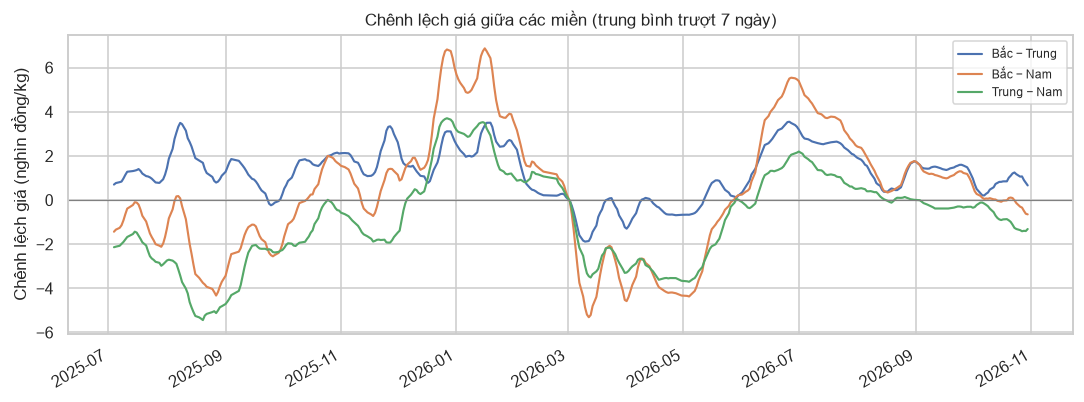

,Cặp miền,Số ngày,Chênh lệch TB (đ/kg),Độ lệch chuẩn,Lớn nhất (đ/kg),Nhỏ nhất (đ/kg),Tương quan mức giá,Tương quan thay đổi hằng ngày
0,Bắc − Trung,402,1235,1255,4733,-2533,0.984,0.759
1,Bắc − Nam,402,404,2928,8358,-5783,0.911,0.546
2,Trung − Nam,402,-832,2103,4443,-6045,0.955,0.699


In [7]:
P = wide("price", obs).dropna()          # chỉ các ngày cả 3 miền cùng có giá
pairs = [("Bac", "Trung"), ("Bac", "Nam"), ("Trung", "Nam")]
ret = wide("price_ffill").diff()          # thay đổi giá hằng ngày
reg_rows = []
for a, b in pairs:
    diff = P[a] - P[b]
    reg_rows.append({
        "Cặp miền": f"{LABEL[a]} − {LABEL[b]}", "Số ngày": len(diff),
        "Chênh lệch TB (đ/kg)": round(diff.mean()), "Độ lệch chuẩn": round(diff.std()),
        "Lớn nhất (đ/kg)": round(diff.max()), "Nhỏ nhất (đ/kg)": round(diff.min()),
        "Tương quan mức giá": round(P[a].corr(P[b]), 3),
        "Tương quan thay đổi hằng ngày": round(ret[a].corr(ret[b]), 3),
    })
region_diff = pd.DataFrame(reg_rows)
save_table(region_diff, "4_1_region_diff.csv")

fig, ax = plt.subplots(figsize=(10, 3.8))
for a, b in pairs:
    ((P[a] - P[b]) / 1000).rolling(7, min_periods=3).mean().plot(ax=ax, label=f"{LABEL[a]} − {LABEL[b]}", lw=1.4)
ax.axhline(0, color="gray", lw=0.8)
ax.set_ylabel("Chênh lệch giá (nghìn đồng/kg)")
ax.set_xlabel("")
ax.set_title("Chênh lệch giá giữa các miền (trung bình trượt 7 ngày)")
ax.legend(fontsize=8)
save_fig(fig, "4_1_region_spread.png")
display(region_diff) if IN_NB else print(region_diff)

## 6. Ma trận tương quan

Biến đại diện mỗi nhóm (giá 3 miền, thức ăn, nhập khẩu, thời tiết, tỷ giá, dầu thô, ASF). Biến vùng (thời tiết) lấy trung bình 3 miền.
Hai ma trận: (a) theo **mức** và (b) theo **thay đổi 30 ngày**. Hai chuỗi cùng có xu hướng có thể tương quan cao dù không liên quan,
nên ma trận (b) quan trọng hơn khi diễn giải. Biến theo tháng (thức ăn, nhập khẩu, ASF) chỉ có 16–17 giá trị khác nhau nên tương quan
rất thiếu tin cậy.

  đã lưu results\tables\4_1_corr_input.csv
  đã lưu results\tables\4_1_corr_matrix_level.csv
  đã lưu results\tables\4_1_corr_matrix_change.csv
  đã lưu results\figures\4_1_corr_matrix_level.png


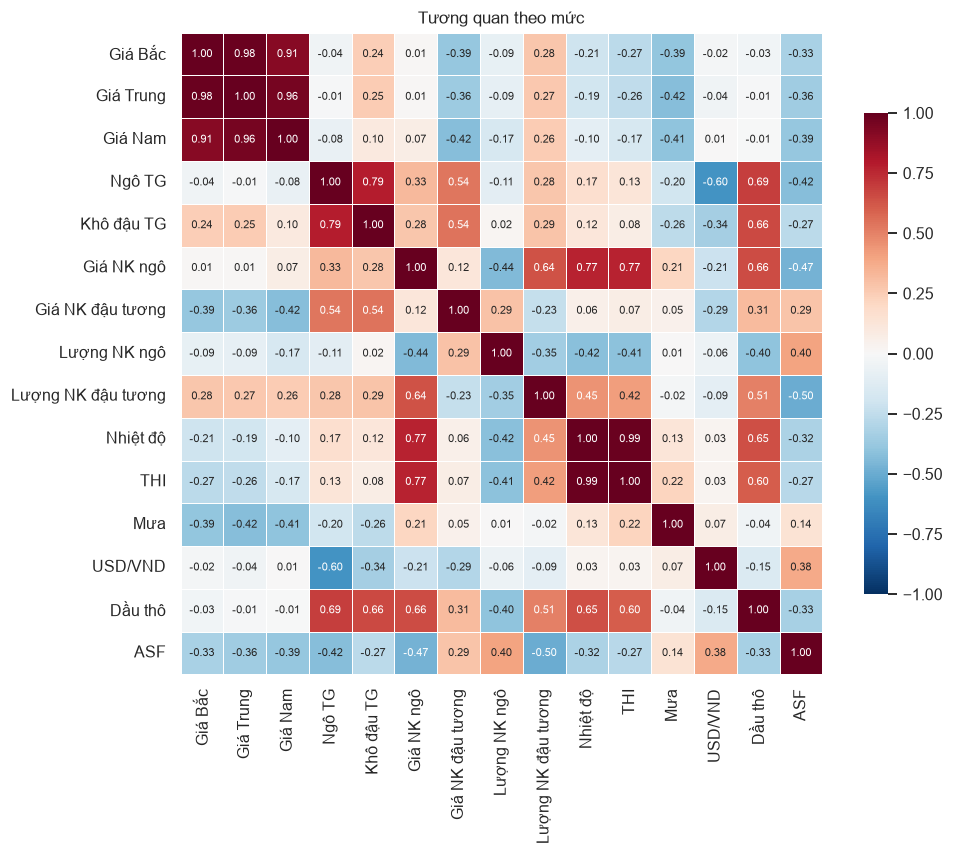

  đã lưu results\figures\4_1_corr_matrix_change.png


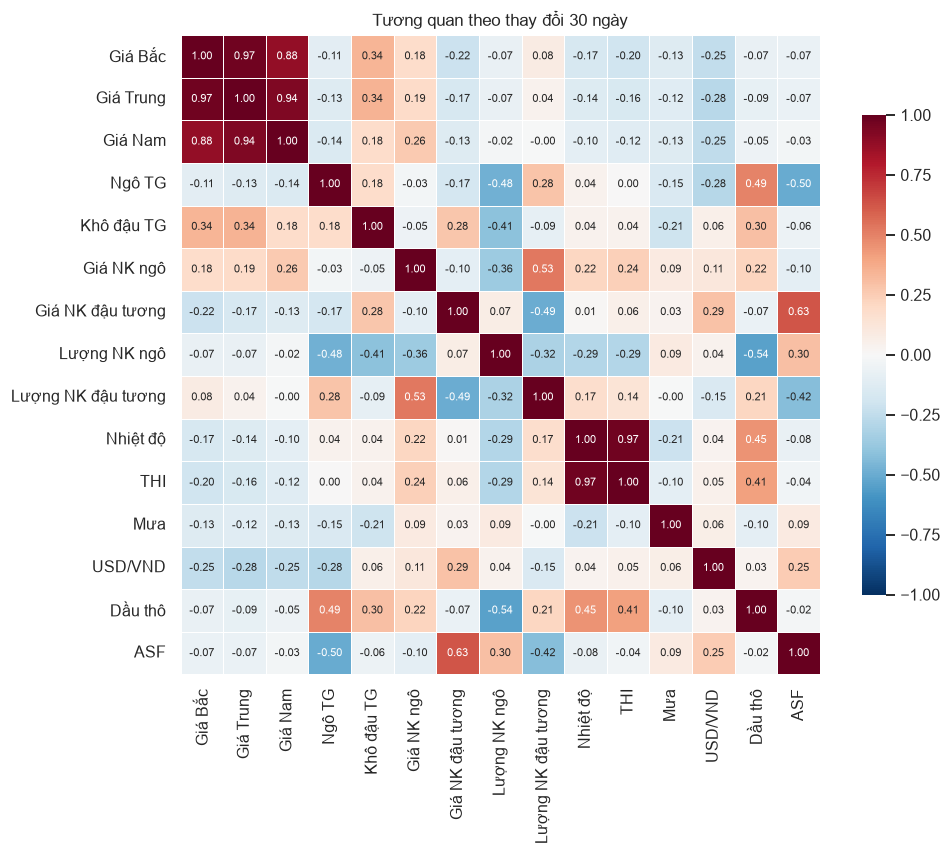

In [8]:
exo = {
    "wb_maize_usd_t": "Ngô TG", "wb_soybean_meal_usd_t": "Khô đậu TG",
    "imp_corn_unit_usd_t": "Giá NK ngô", "imp_soybean_unit_usd_t": "Giá NK đậu tương",
    "imp_corn_volume_kt": "Lượng NK ngô", "imp_soybean_volume_kt": "Lượng NK đậu tương",
    "temp_mean": "Nhiệt độ", "thi": "THI", "rain_mm": "Mưa",
    "usd_vnd": "USD/VND", "wb_crude_usd_bbl": "Dầu thô", "asf_active_share": "ASF",
}
N = wide("price_ffill").rename(columns={r: f"Giá {LABEL[r]}" for r in REGIONS})
N = N.join(df.groupby("date")[list(exo)].mean().rename(columns=exo))
N = N.dropna()
save_table(N.reset_index().rename(columns={"date": "Ngày"}), "4_1_corr_input.csv")   # để kiểm tra lại bằng Excel (CORREL)

def heat(corr, title, name):
    fig, ax = plt.subplots(figsize=(9.5, 7.8))
    sns.heatmap(corr, annot=True, fmt=".2f", annot_kws={"size": 7.5}, cmap="RdBu_r",
                vmin=-1, vmax=1, square=True, linewidths=0.4, cbar_kws={"shrink": 0.75}, ax=ax)
    ax.set_title(title)
    save_fig(fig, name)

corr_level = N.corr().round(3)
corr_change = N.diff(30).dropna().corr().round(3)
save_table(corr_level.reset_index().rename(columns={"index": "Biến"}), "4_1_corr_matrix_level.csv")
save_table(corr_change.reset_index().rename(columns={"index": "Biến"}), "4_1_corr_matrix_change.csv")
heat(corr_level, "Tương quan theo mức", "4_1_corr_matrix_level.png")
heat(corr_change, "Tương quan theo thay đổi 30 ngày", "4_1_corr_matrix_change.png")

## 7. Tương quan trễ thức ăn–giá heo (lag 30, 60, 90 ngày)

Tương quan giữa giá heo hôm nay và giá thức ăn ở thời điểm t, t−30, t−60, t−90 (các cột `*_lag30/60/90` của E2).
Mọi độ trễ dùng **cùng một tập ngày** (cả 4 cột đều có giá trị) để so sánh công bằng.
Lưu ý: dữ liệu World Bank đã trễ 32–65 ngày so với kỳ tham chiếu, nên "lag 30" thực tế là trễ khoảng 62–95 ngày.
Đây chỉ là mô tả, không chứng minh quan hệ nhân quả; RQ2 sẽ do ablation của P4 trả lời.

  đã lưu results\tables\4_1_lag_corr.csv
  đã lưu results\figures\4_1_lag_corr.png


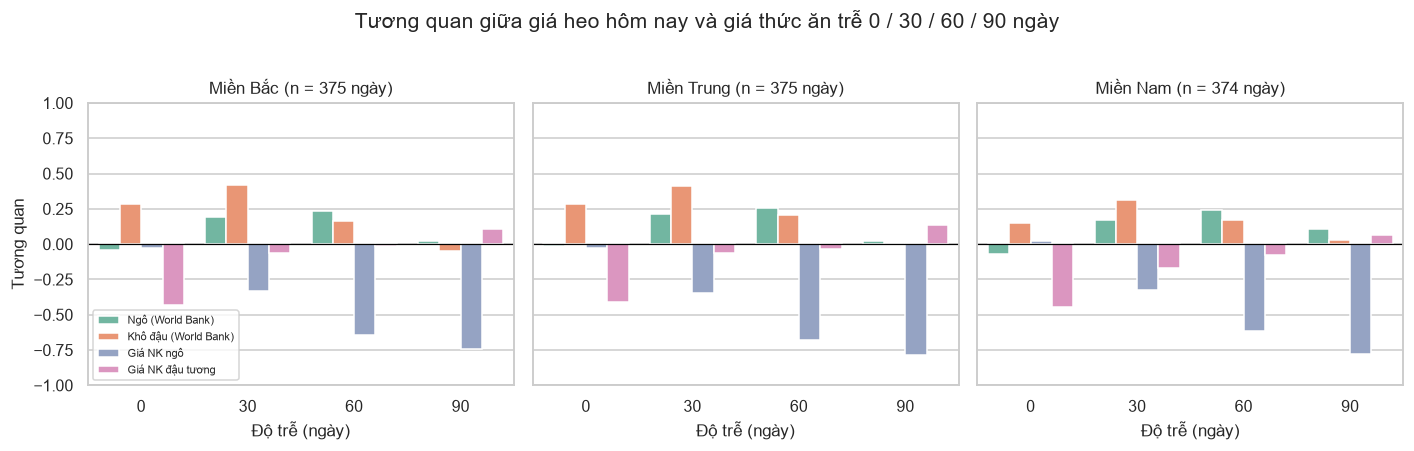

Độ trễ (ngày)                  0      30     60     90
Miền  Thức ăn                                         
Bắc   Giá NK ngô           -0.027 -0.330 -0.640 -0.744
      Giá NK đậu tương     -0.434 -0.064 -0.015  0.111
      Khô đậu (World Bank)  0.284  0.419  0.167 -0.046
      Ngô (World Bank)     -0.044  0.196  0.233  0.020
Nam   Giá NK ngô            0.021 -0.322 -0.618 -0.780
      Giá NK đậu tương     -0.448 -0.171 -0.076  0.062
      Khô đậu (World Bank)  0.148  0.313  0.171  0.027
      Ngô (World Bank)     -0.069  0.173  0.242  0.104
Trung Giá NK ngô           -0.025 -0.349 -0.677 -0.788
      Giá NK đậu tương     -0.410 -0.061 -0.036  0.138
      Khô đậu (World Bank)  0.288  0.414  0.209  0.004
      Ngô (World Bank)     -0.016  0.211  0.253  0.023

In [9]:
FEEDS = {
    "wb_maize_usd_t": "Ngô (World Bank)", "wb_soybean_meal_usd_t": "Khô đậu (World Bank)",
    "imp_corn_unit_usd_t": "Giá NK ngô", "imp_soybean_unit_usd_t": "Giá NK đậu tương",
}
LAGS = [0, 30, 60, 90]
lag_rows = []
for r in REGIONS:
    x = obs[obs["region"] == r]
    cols = [f if L == 0 else f"{f}_lag{L}" for f in FEEDS for L in LAGS]
    x = x.dropna(subset=cols)                       # cùng một tập ngày cho mọi độ trễ
    for f, fname in FEEDS.items():
        for L in LAGS:
            c = f if L == 0 else f"{f}_lag{L}"
            lag_rows.append({"Miền": LABEL[r], "Thức ăn": fname, "Độ trễ (ngày)": L,
                             "Tương quan": round(x["price"].corr(x[c]), 3), "n": len(x)})
lagcorr = pd.DataFrame(lag_rows)
save_table(lagcorr, "4_1_lag_corr.csv")

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, r in zip(axes, REGIONS):
    d = lagcorr[lagcorr["Miền"] == LABEL[r]]
    sns.barplot(data=d, x="Độ trễ (ngày)", y="Tương quan", hue="Thức ăn", ax=ax, palette="Set2")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"Miền {LABEL[r]} (n = {d['n'].iloc[0]} ngày)")
    ax.set_ylim(-1, 1)
    if ax is not axes[0]:
        ax.get_legend().remove()
        ax.set_ylabel("")
axes[0].legend(fontsize=7, loc="lower left")
fig.suptitle("Tương quan giữa giá heo hôm nay và giá thức ăn trễ 0 / 30 / 60 / 90 ngày", y=1.02)
save_fig(fig, "4_1_lag_corr.png")
display(lagcorr.pivot_table(index=["Miền", "Thức ăn"], columns="Độ trễ (ngày)", values="Tương quan")) if IN_NB else None

In [10]:
print("Hoàn tất. Bảng:", sorted(p.name for p in TAB.glob("4_1_*.csv")))
print("Hình:", sorted(p.name for p in FIG.glob("4_1_*.png")))

Hoàn tất. Bảng: ['4_1_adf.csv', '4_1_corr_input.csv', '4_1_corr_matrix_change.csv', '4_1_corr_matrix_level.csv', '4_1_desc_by_region.csv', '4_1_lag_corr.csv', '4_1_monthly_mean.csv', '4_1_peak_and_end.csv', '4_1_price_wide.csv', '4_1_region_diff.csv', '4_1_tet_effect.csv']
Hình: ['4_1_corr_matrix_change.png', '4_1_corr_matrix_level.png', '4_1_lag_corr.png', '4_1_price_by_region.png', '4_1_price_distribution.png', '4_1_region_spread.png', '4_1_tet_window.png']
